
# Machine Learning Assignment 3
### Decision Trees, Bagging, and Random Forests (Classification + Regression)


### Report Structure

1. Theoretical background and mathematical formulations  
2. Classification task (Car Evaluation): EDA, modeling, interpretation  
3. Regression task (Boston Housing): EDA, modeling, interpretation  
4. Advanced visual diagnostics (confusion matrices, learning curves, residual analysis)  
5. Feature importance analysis and cross-model comparison



## 1. Theoretical Foundations

### 1.1 Decision Tree 

Let the training set be **Dataset D** with class labels (for example, Play = Yes/No).

A decision tree starts from D at the root and recursively creates subsets by splitting on attributes.
At each node, we compute impurity and choose the split with maximum **Gain(attribute)**.

- **Entropy of Dataset D**:

$$Entropy(D) = -\sum_{i=1}^{c} p_i \log_2 p_i$$

where $p_i$ is the probability that a tuple in D belongs to class $C_i$.

- **Entropy after splitting on attribute A**:

$$Entropy(A) = \sum_{v \in Values(A)} \frac{|D_v|}{|D|} Entropy(D_v)$$

where $D_v$ is the subset of D for attribute value $v$.

- **Information Gain of attribute A**:

$$Gain(A) = Entropy(D) - Entropy(A)$$

The attribute with highest Gain is selected for the split.

### 1.2 Split Further vs Pure Subset

After a split, each child subset is checked:

- If all tuples in a subset belong to one class, it is a **Pure Subset** (leaf node).
- If classes are mixed, we **Split Further** (for example, call them D1, D2, ...).

This process continues recursively until subsets become pure or a stopping condition is met.

### 1.3 Bias-Variance Perspective (Core Theory)

This assignment is fundamentally about the bias-variance tradeoff:

- **Single Decision Tree**: typically low bias at high depth but high variance (sensitive to sample perturbations).
- **Bagging**: keeps tree bias similar but reduces variance by averaging many bootstrap trees.
- **Random Forest**: further reduces variance by decorrelating trees through random feature subsampling at each split.

So, expected progression is: flexible tree learns structure, bagging stabilizes it, and random forest improves stability further when tree correlation is reduced.

### 1.4 Overfitting and Regularization

Very deep trees can overfit Dataset D. We control complexity using:

- Maximum depth $T$ (classification task)
- Minimum terminal-node samples $S$ (regression task; here fixed to $S=4$)

### 1.5 Regression Tree Criterion

For regression, target values are continuous, so we split to reduce node error (variance), commonly via RSS:

$$RSS = \sum_{i \in R_1}(y_i-\hat{y}_{R_1})^2 + \sum_{i \in R_2}(y_i-\hat{y}_{R_2})^2$$

The best split is the one with largest reduction in RSS.

### 1.6 Bagging

Bagging builds $B$ trees on bootstrap samples of Dataset D and aggregates predictions:

- Classification: majority vote across $B$ trees
- Regression: average of $B$ tree outputs

Bagging mainly reduces variance and improves generalization.

### 1.7 Random Forest

Random Forest = Bagging + random feature subset at each split.

If total number of features is $d$, each split uses only $m$ randomly selected features:

- Classification commonly uses $m \approx \sqrt{d}$ to increase tree diversity.
- Regression commonly uses a larger fraction (often around $d/3$ in spirit), balancing split strength and decorrelation.
- In this notebook: classification uses **$m=4$**, regression uses **$m=7$**.

This decorrelates trees and usually gives better ensemble performance than plain bagging when base trees are otherwise strongly correlated.


## 2. Setup 

### Why this setup matters

Before modeling, we standardize the coding environment and imports so that results are reproducible and comparable. Using a fixed random seed ensures that train/validation splits and ensemble sampling are consistent across runs, which is important when discussing performance differences scientifically.

In [1]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from urllib.request import urlopen

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingClassifier, BaggingRegressor, RandomForestClassifier, RandomForestRegressor

from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, train_test_split, learning_curve
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    make_scorer,
)

RANDOM_STATE = 42

# Professional styling defaults
sns.set_theme(style="whitegrid", context="talk", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"


## 3. Utility Functions

### Conceptual intent of utility functions

These helper functions separate *experimental logic* from *visualization and selection logic*. This improves clarity and reduces coding noise, so each later section can focus on a modeling question (for example, "what depth should we choose?") rather than repeated plotting boilerplate.

In [2]:

def plot_line(x, y, title, xlabel, ylabel, marker='o'):
    plt.figure(figsize=(10, 6))
    plt.plot(x, y, marker=marker, linewidth=2.5)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()


def best_by(values, scores, maximize=True):
    idx = int(np.argmax(scores) if maximize else np.argmin(scores))
    return values[idx], scores[idx]


def draw_learning_curve(estimator, X, y, cv, scoring, title):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator,
        X,
        y,
        cv=cv,
        scoring=scoring,
        train_sizes=np.linspace(0.1, 1.0, 8),
        n_jobs=-1,
        random_state=RANDOM_STATE if "random_state" in estimator.get_params() else None,
    )

    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)

    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, train_mean, 'o-', label='Training score', linewidth=2)
    plt.plot(train_sizes, val_mean, 'o-', label='Validation score', linewidth=2)
    plt.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.15)
    plt.fill_between(train_sizes, val_mean-val_std, val_mean+val_std, alpha=0.15)
    plt.title(title)
    plt.xlabel('Training Examples')
    plt.ylabel(scoring)
    plt.legend()
    plt.tight_layout()
    plt.show()


---
# Part A: Classification (Car Evaluation Dataset)

## 4. Data Loading (Directly from URL)

In [3]:

car_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data"
car_cols = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
car_df = pd.read_csv(car_url, header=None, names=car_cols)

print("Car dataset shape:", car_df.shape)
car_df.head()


Car dataset shape: (1728, 7)


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## 5. Comprehensive EDA for Classification

In [4]:

display(car_df.describe(include='all').T)

print("Missing values per column:")
print(car_df.isna().sum())


,count,unique,top,freq
buying,1728,4,vhigh,432
maint,1728,4,vhigh,432
doors,1728,4,2,432
persons,1728,3,2,576
lug_boot,1728,3,small,576
safety,1728,3,low,576
class,1728,4,unacc,1210


Missing values per column:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


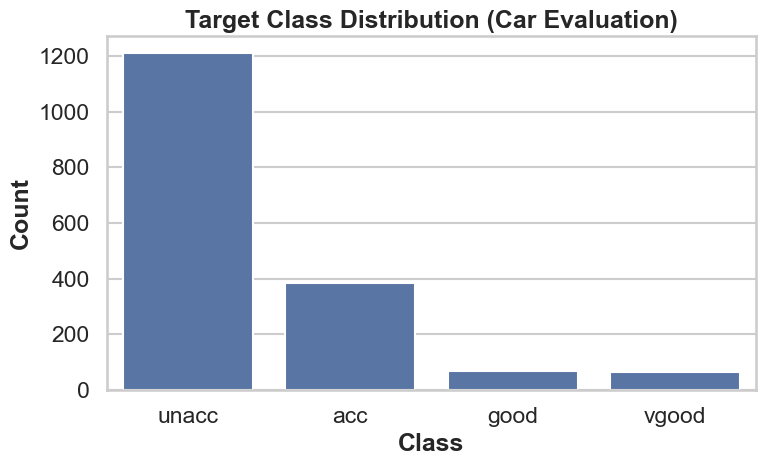

Class proportions:  class
unacc    0.700231
acc      0.222222
good     0.039931
vgood    0.037616
Name: proportion, dtype: float64


In [5]:

# Target distribution
plt.figure(figsize=(8, 5))
order = car_df['class'].value_counts().index
sns.countplot(data=car_df, x='class', order=order)
plt.title('Target Class Distribution (Car Evaluation)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

class_props = car_df['class'].value_counts(normalize=True).rename('proportion')
print("Class proportions: ", class_props)


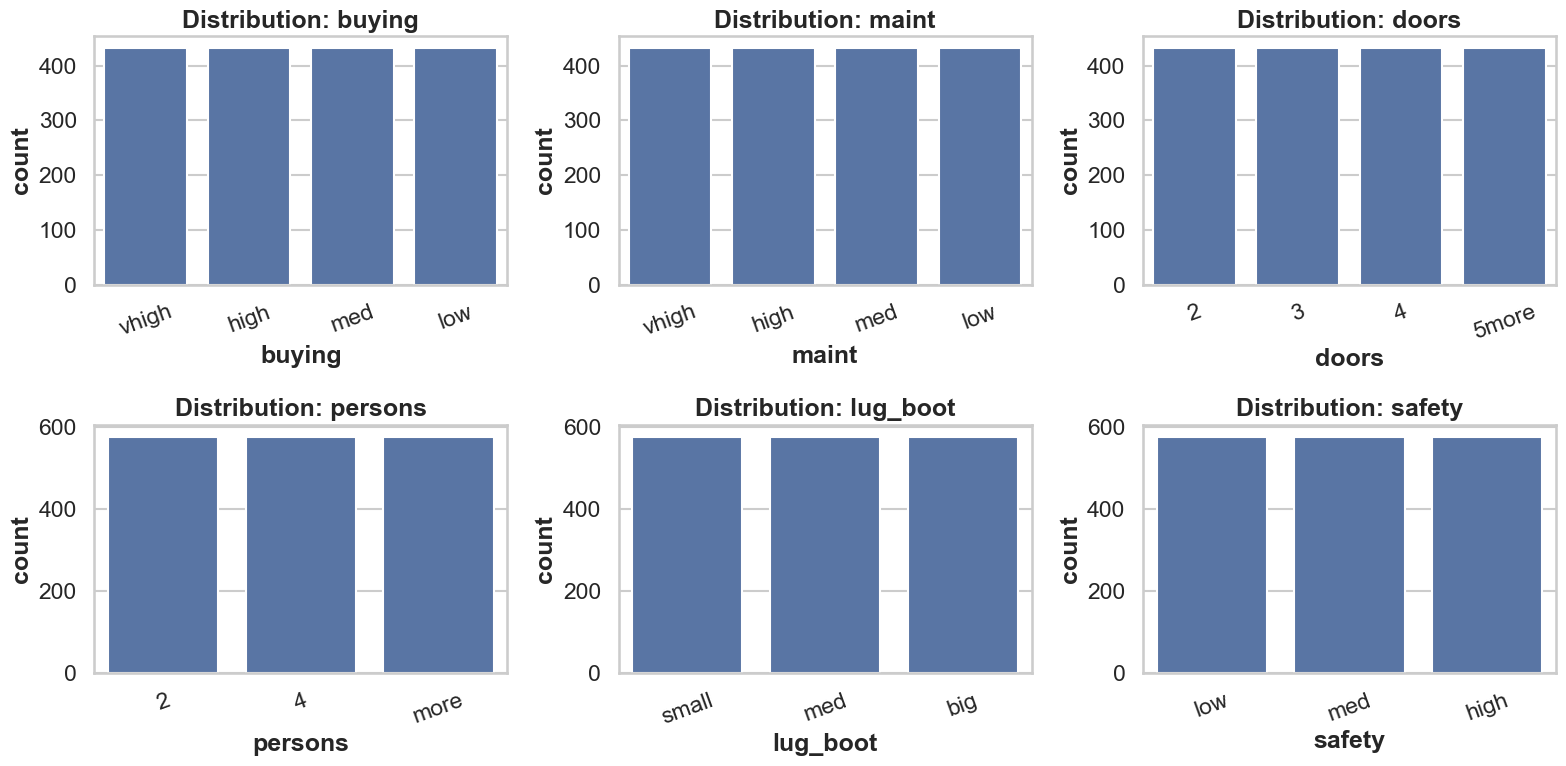

In [6]:

# Feature-category distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for i, col in enumerate([c for c in car_df.columns if c != 'class']):
    sns.countplot(data=car_df, x=col, ax=axes[i], order=car_df[col].value_counts().index)
    axes[i].set_title(f"Distribution: {col}")
    axes[i].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()


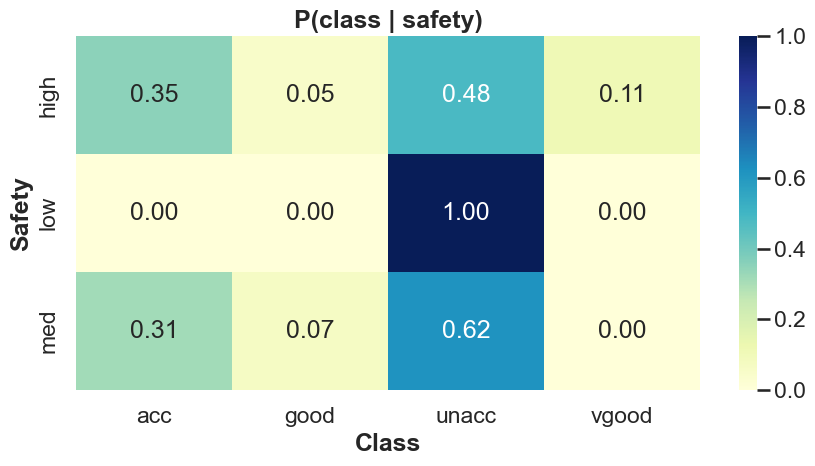

class,acc,good,unacc,vgood
safety,,,,
high,0.354167,0.052083,0.480903,0.112847
low,0.000000,0.000000,1.000000,0.000000
med,0.312500,0.067708,0.619792,0.000000


In [7]:

# Class-conditioned view for one key feature (safety) to aid interpretation
ct = pd.crosstab(car_df['safety'], car_df['class'], normalize='index')
plt.figure(figsize=(9, 5))
sns.heatmap(ct, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('P(class | safety)')
plt.xlabel('Class')
plt.ylabel('Safety')
plt.tight_layout()
plt.show()

display(ct)


### 5.1 Statistical Interpretation

The Car Evaluation dataset contains $1728$ observations and $7$ variables (6 predictors and 1 target). The target distribution is imbalanced, with `unacc` comprising the majority class and `good`/`vgood` representing minority classes.

Given this imbalance, performance estimation via stratified cross-validation is methodologically appropriate because it preserves class proportions across folds. The conditional distribution analysis $P(\text{class} \mid \text{safety})$ indicates strong class separation by safety level, providing empirical justification for tree-based partitioning on categorical attributes.

## 6. Preprocessing and Validation Design

### Conceptual reasoning: encoding and validation

The car dataset is categorical, so one-hot encoding is required to convert category levels into split-ready numeric indicators for scikit-learn models.

`StratifiedKFold` is chosen because class frequencies are imbalanced. Stratification preserves class proportions in each fold, giving a more reliable estimate of generalization than plain K-fold in imbalanced classification.

In [8]:

X_car = car_df.drop(columns=['class'])
y_car = car_df['class']

cat_cols = X_car.columns.tolist()
preprocess_car = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


## 7. Decision Tree (Entropy) with Depth Tuning

### Conceptual Reasoning: Depth Tuning for Decision Trees

Model complexity was controlled through maximum depth $T$. Cross-validated accuracy increased substantially from shallow configurations and reached a near-plateau at larger depths.

Empirical result: the optimal configuration was $T=14$, yielding mean CV accuracy $0.9780$. This is a bias-variance signature:
- At small depth, the tree underfits (high bias), so CV accuracy is lower.
- As depth increases, the model captures genuine structure in Dataset D, so CV accuracy rises.
- Beyond a point, additional depth mostly increases variance; CV accuracy stabilizes and can eventually decline if fold-specific noise is learned.

So CV accuracy is not expected to decrease immediately with depth; rising-then-plateau behavior is methodologically consistent with controlled complexity growth.

Best depth T: 14
Best CV accuracy (Decision Tree): 0.9780


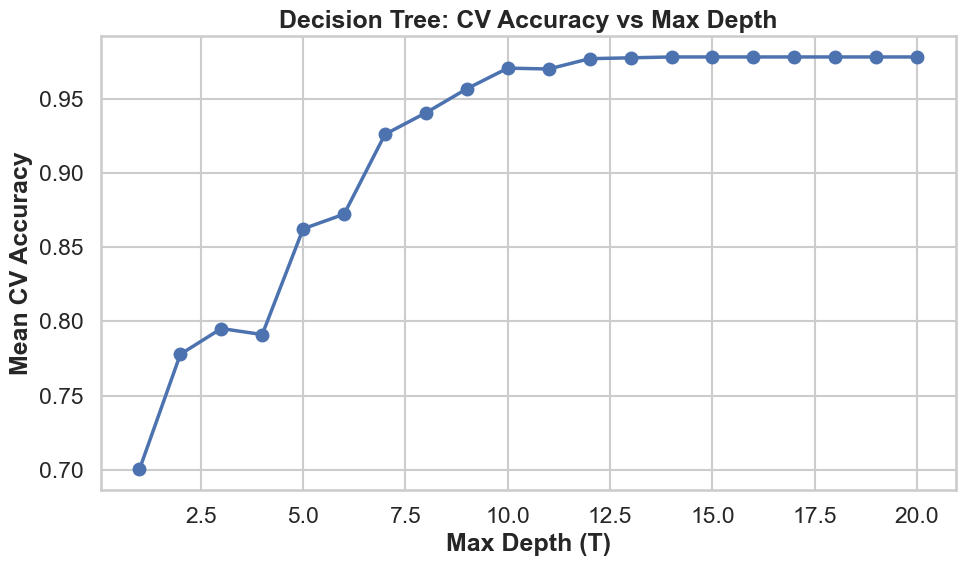

In [9]:

depth_values = list(range(1, 21))
acc_depth = []

for T in depth_values:
    pipe = Pipeline([
        ('prep', preprocess_car),
        ('dt', DecisionTreeClassifier(criterion='entropy', max_depth=T, random_state=RANDOM_STATE))
    ])
    score = cross_val_score(pipe, X_car, y_car, scoring='accuracy', cv=cv_cls, n_jobs=-1).mean()
    acc_depth.append(score)

best_T, best_tree_cv_acc = best_by(depth_values, acc_depth, maximize=True)
print(f"Best depth T: {best_T}")
print(f"Best CV accuracy (Decision Tree): {best_tree_cv_acc:.4f}")

plot_line(depth_values, acc_depth,
          'Decision Tree: CV Accuracy vs Max Depth',
          'Max Depth (T)',
          'Mean CV Accuracy')


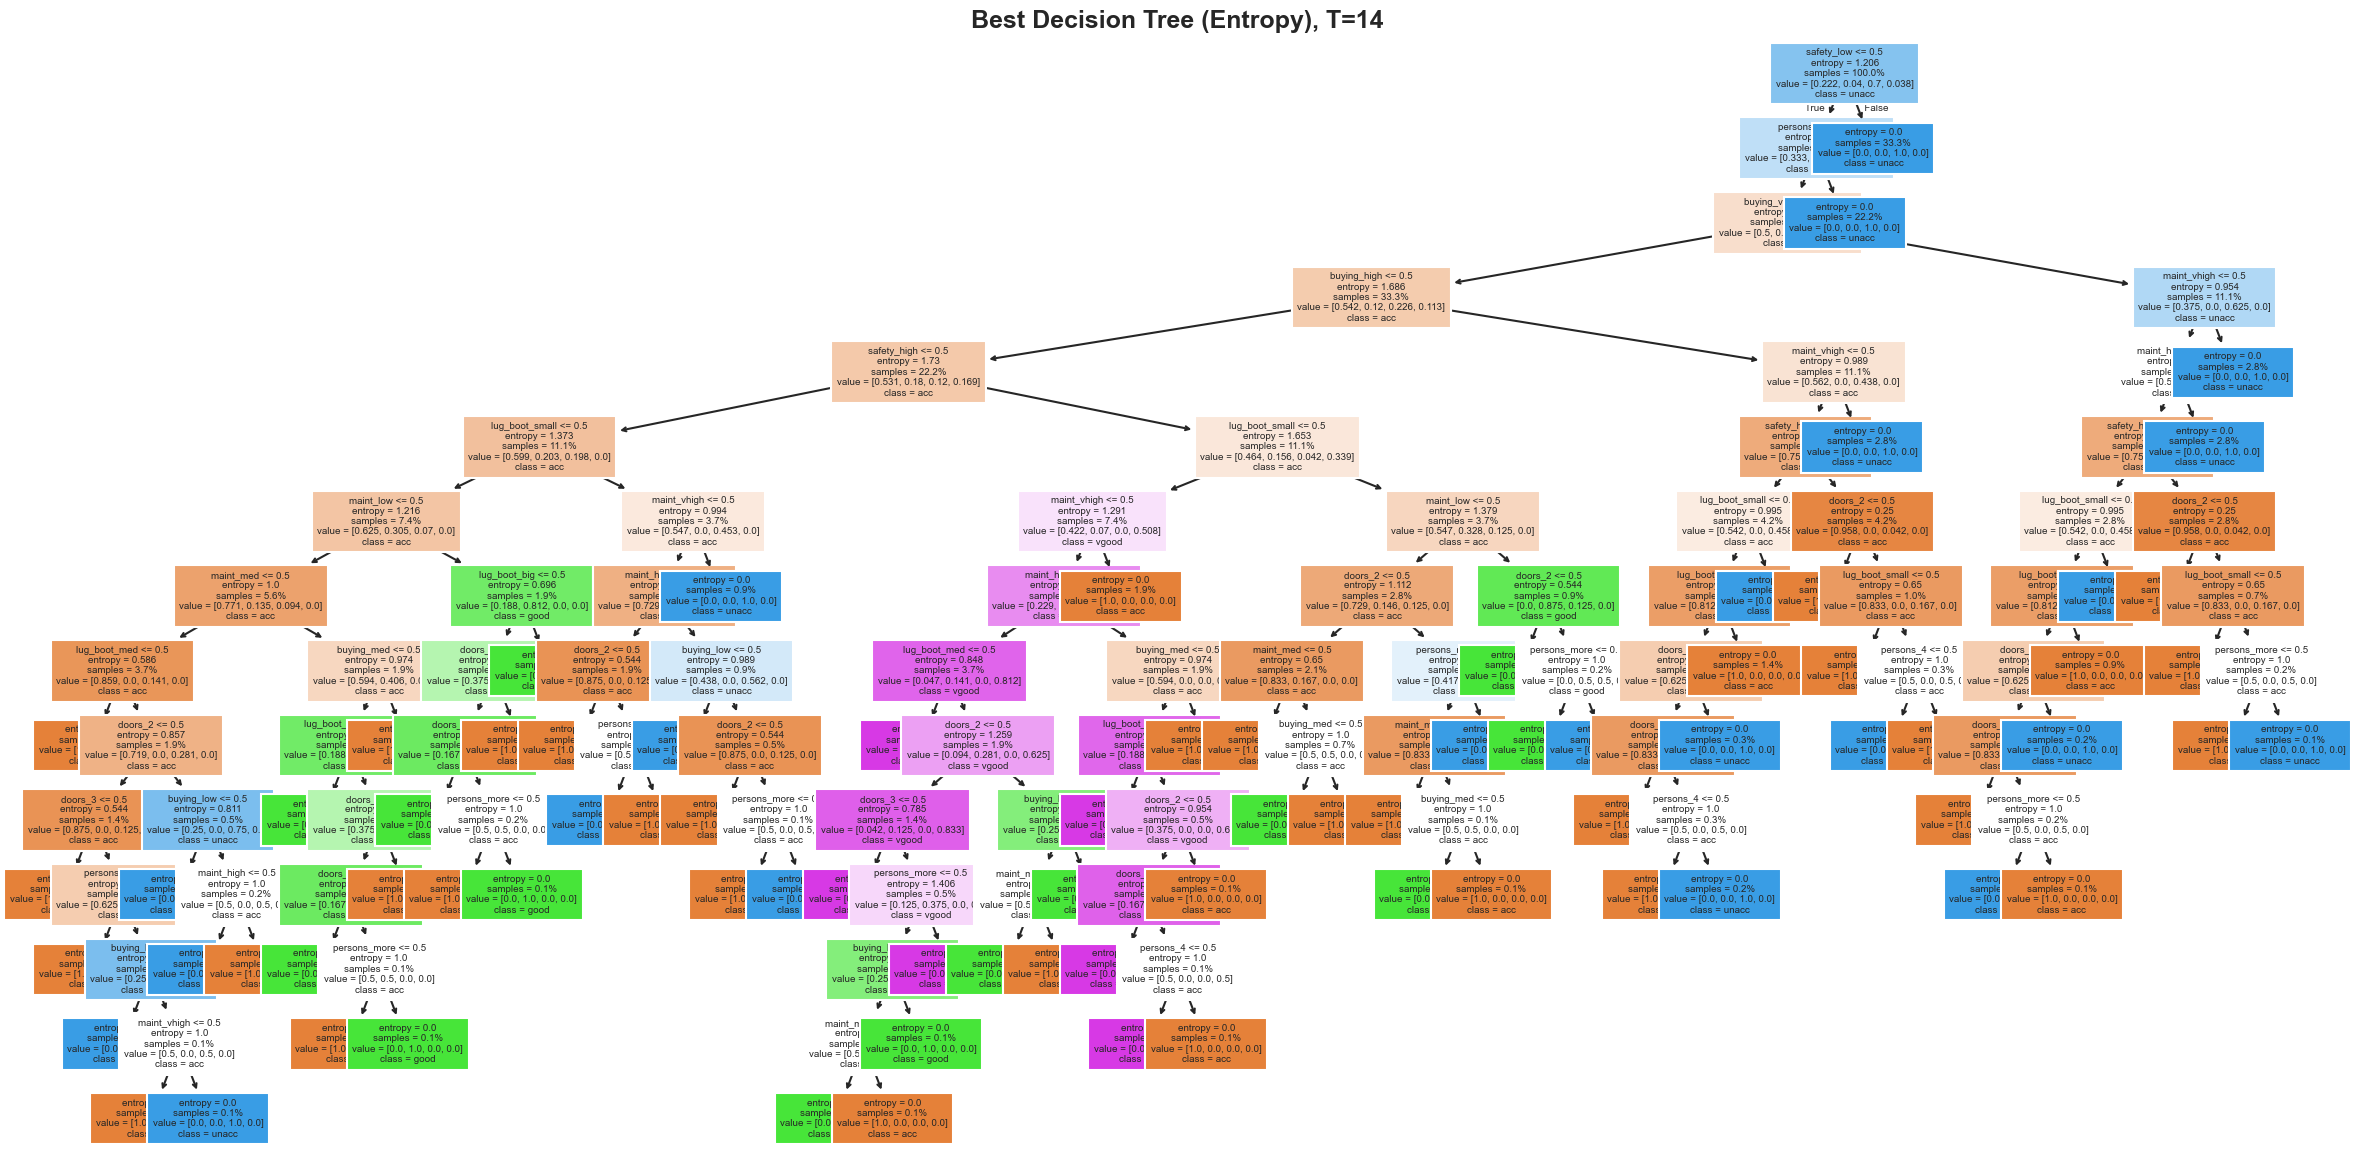

In [10]:

# Visualize trained tree for interpretability
enc = OneHotEncoder(handle_unknown='ignore')
X_car_enc = enc.fit_transform(X_car)
feature_names_car = enc.get_feature_names_out(cat_cols)

dt_best = DecisionTreeClassifier(criterion='entropy', max_depth=best_T, random_state=RANDOM_STATE)
dt_best.fit(X_car_enc, y_car)

plt.figure(figsize=(24, 12))
plot_tree(
    dt_best,
    feature_names=feature_names_car,
    class_names=sorted(y_car.unique()),
    filled=True,
    fontsize=7,
    proportion=True
)
plt.title(f'Best Decision Tree (Entropy), T={best_T}')
plt.tight_layout()
plt.show()


### Interpretation of the Visualized Decision Tree

The tree plot should be interpreted from top to bottom: root and near-root splits are the highest-information partitions (largest impurity reduction early in training).

In this dataset, safety- and capacity-related conditions (for example, `safety` and `persons` indicators) typically appear near the top, which is consistent with strong class-separation signal in EDA.

Analytically, this means:
- Early splits create large reductions in Entropy on Dataset D.
- Some branches become close to pure quickly (especially for unsafe/low-capacity patterns).
- Remaining mixed branches require deeper split further steps using additional attributes (`buying`, `maint`, `lug_boot`, etc.) to resolve minority-class boundaries.

## 8. Bagging (Tune Number of Trees B)

### Conceptual Reasoning: Bagging in Classification

Bagging was evaluated by varying the number of estimators $B$. The key mechanism is variance reduction: each tree is high-variance, but averaging many bootstrap trees suppresses sample-specific fluctuations.

Empirical result: the best-performing setting was $B=50$, with minimal gain for larger $B$. This stabilization is expected because ensemble variance decreases roughly as correlation-adjusted averaging accumulates, then reaches diminishing returns.

Interpretation: once variance has been reduced sufficiently, increasing $B$ mainly adds computational cost without meaningful accuracy improvement.

Best B (Bagging): 50
Best CV accuracy (Bagging): 0.9809


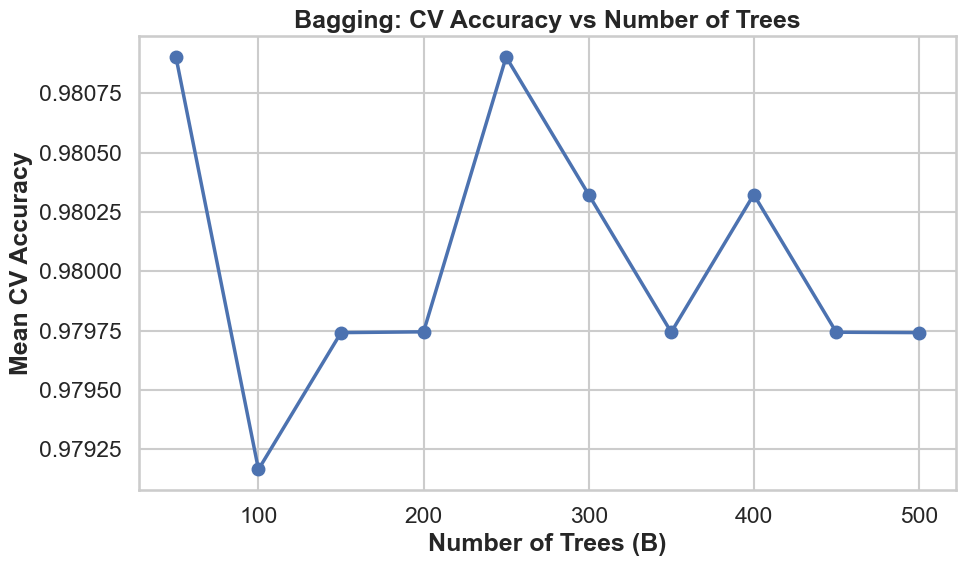

In [11]:

B_values = list(range(50, 501, 50))
acc_bag = []

for B in B_values:
    bag_pipe = Pipeline([
        ('prep', preprocess_car),
        ('bag', BaggingClassifier(
            estimator=DecisionTreeClassifier(criterion='entropy', max_depth=best_T, random_state=RANDOM_STATE),
            n_estimators=B,
            bootstrap=True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
    score = cross_val_score(bag_pipe, X_car, y_car, scoring='accuracy', cv=cv_cls, n_jobs=-1).mean()
    acc_bag.append(score)

best_B_cls, best_bag_acc = best_by(B_values, acc_bag, maximize=True)
print(f"Best B (Bagging): {best_B_cls}")
print(f"Best CV accuracy (Bagging): {best_bag_acc:.4f}")

plot_line(B_values, acc_bag,
          'Bagging: CV Accuracy vs Number of Trees',
          'Number of Trees (B)',
          'Mean CV Accuracy')


## 9. Random Forest (m = 4)

### Conceptual Reasoning: Random Forest in Classification

Random Forest extends bagging by adding feature-level randomness at each split, which reduces inter-tree correlation. Lower correlation increases the variance-reduction benefit of averaging, often improving generalization over plain bagging.

Why $m$ matters:
- Larger $m$: stronger individual trees but higher correlation across trees.
- Smaller $m$: weaker individual trees but better decorrelation.
- Classification often uses $m \approx \sqrt{d}$ as a practical tradeoff; here we use $m=4$ per assignment setup.

Empirical result: with $m=4$ and $B=50$, CV accuracy was $0.9635$. Relative to bagging, this indicates that for this dataset the decorrelation-strength tradeoff did not outperform unrestricted-feature bagging, likely because strongly informative predictors benefit from frequent availability. This is a valid bias-variance outcome, not a contradiction.

In [12]:

rf_cls_pipe = Pipeline([
    ('prep', preprocess_car),
    ('rf', RandomForestClassifier(
        n_estimators=best_B_cls,
        max_features=4,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_cls_cv_acc = cross_val_score(rf_cls_pipe, X_car, y_car, scoring='accuracy', cv=cv_cls, n_jobs=-1).mean()
print(f"Random Forest CV accuracy (m=4, B={best_B_cls}): {rf_cls_cv_acc:.4f}")


Random Forest CV accuracy (m=4, B=50): 0.9635


## 10. Advanced Evaluation: Confusion Matrix and Learning Curves

### Diagnostic Value Beyond Aggregate Accuracy

The hold-out accuracy of the Random Forest classifier was $0.9711$, indicating strong overall predictive performance. However, class-resolved diagnostics provide materially richer evidence.

The confusion matrix shows dominant correct classification for `unacc`, with residual misclassification concentrated in minority categories (notably `good` and `vgood`). Therefore, class-wise error analysis is necessary to assess practical reliability under imbalance, where aggregate accuracy may obscure minority-class degradation.

Hold-out accuracy (Random Forest): 0.9711
Classification report: 
              precision    recall  f1-score   support

         acc       0.93      0.97      0.95        77
        good       0.87      0.93      0.90        14
       unacc       1.00      0.98      0.99       242
       vgood       0.91      0.77      0.83        13

    accuracy                           0.97       346
   macro avg       0.92      0.91      0.92       346
weighted avg       0.97      0.97      0.97       346



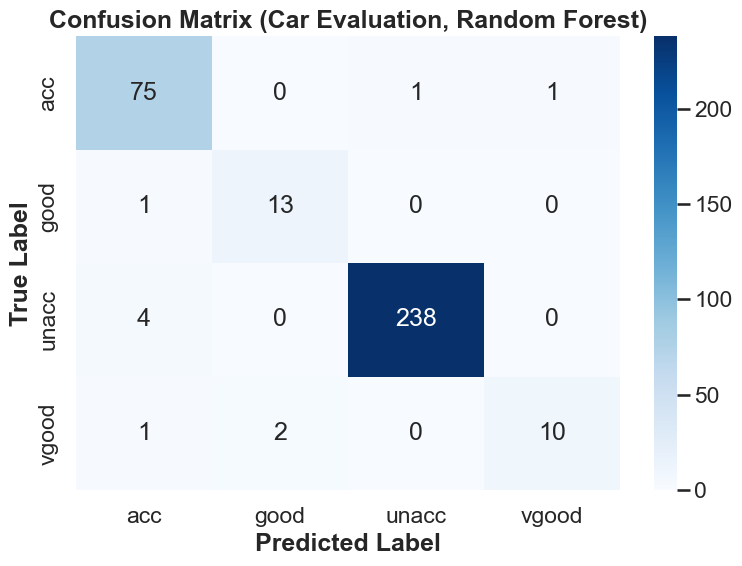

In [13]:

# Hold-out split for confusion matrix interpretability
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_car, y_car, test_size=0.2, stratify=y_car, random_state=RANDOM_STATE
)

rf_cls_pipe.fit(X_train_c, y_train_c)
y_pred_c = rf_cls_pipe.predict(X_test_c)

acc_test = accuracy_score(y_test_c, y_pred_c)
print(f"Hold-out accuracy (Random Forest): {acc_test:.4f}")
print("Classification report: ")
print(classification_report(y_test_c, y_pred_c))

cm = confusion_matrix(y_test_c, y_pred_c, labels=sorted(y_car.unique()))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y_car.unique()), yticklabels=sorted(y_car.unique()))
plt.title('Confusion Matrix (Car Evaluation, Random Forest)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()


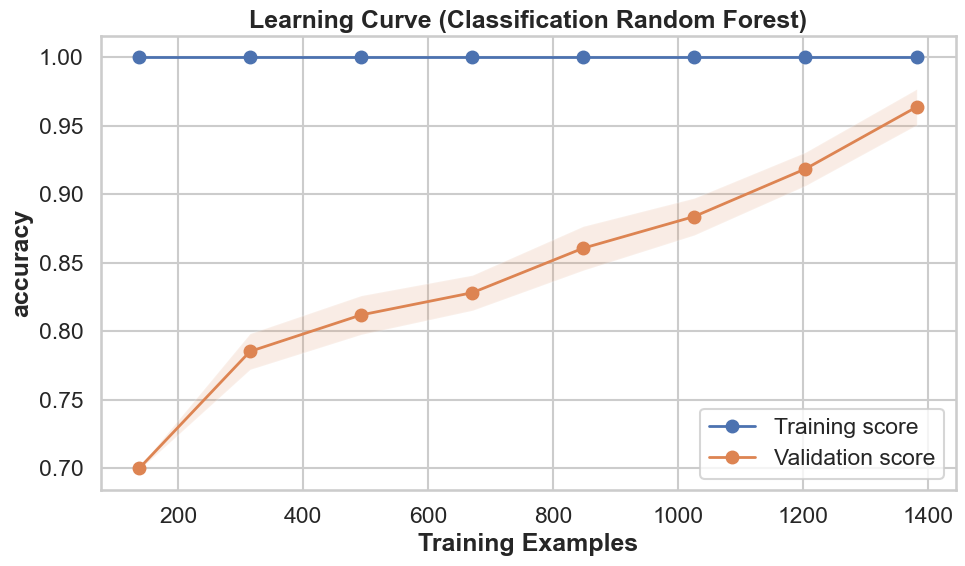

In [14]:

# Learning curve for best classification model
draw_learning_curve(
    estimator=rf_cls_pipe,
    X=X_car,
    y=y_car,
    cv=cv_cls,
    scoring='accuracy',
    title='Learning Curve (Classification Random Forest)'
)


## 11. Feature Importance Analysis (Classification RF)

### Interpreting impurity-based feature importance

Random-forest importance scores summarize average impurity reduction attributed to each feature. They are useful for ranking influential variables, but should be interpreted cautiously for one-hot encoded categories because related dummy variables can split importance across levels.

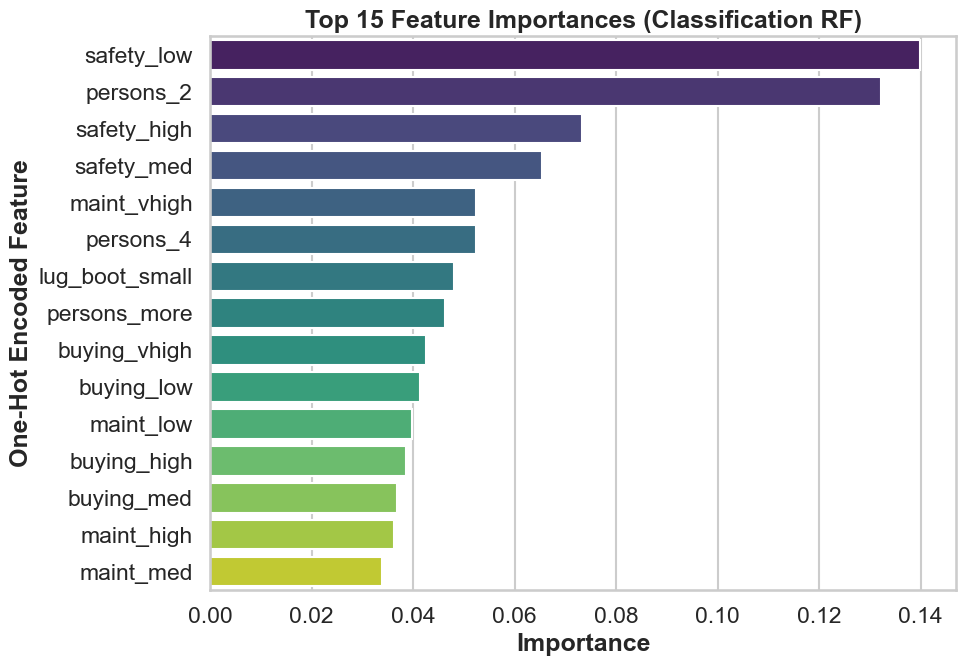

,importance
safety_low,0.139964
persons_2,0.132128
safety_high,0.073235
safety_med,0.065447
maint_vhigh,0.052471
persons_4,0.052308
lug_boot_small,0.047957
persons_more,0.046345
buying_vhigh,0.042518
buying_low,0.041332


In [15]:

rf_cls_pipe.fit(X_car, y_car)
rf_model = rf_cls_pipe.named_steps['rf']
encoder = rf_cls_pipe.named_steps['prep'].named_transformers_['cat']
feature_names = encoder.get_feature_names_out(cat_cols)

importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)

top_n = 15
plt.figure(figsize=(10, 7))
sns.barplot(x=importances.head(top_n).values, y=importances.head(top_n).index, palette='viridis')
plt.title(f'Top {top_n} Feature Importances (Classification RF)')
plt.xlabel('Importance')
plt.ylabel('One-Hot Encoded Feature')
plt.tight_layout()
plt.show()

display(importances.head(top_n).to_frame('importance'))


## 12. Classification Model Comparison Table

In [16]:

classification_results = pd.DataFrame([
    ["Decision Tree (Entropy)", f"T={best_T}", best_tree_cv_acc],
    ["Bagging", f"T={best_T}, B={best_B_cls}", best_bag_acc],
    ["Random Forest", f"m=4, B={best_B_cls}", rf_cls_cv_acc],
], columns=["Model", "Configuration", "CV Accuracy"])

classification_results = classification_results.sort_values("CV Accuracy", ascending=False).reset_index(drop=True)
classification_results.index = classification_results.index + 1
classification_results


,Model,Configuration,CV Accuracy
1,Bagging,"T=14, B=50",0.980903
2,Decision Tree (Entropy),T=14,0.977998
3,Random Forest,"m=4, B=50",0.963539


---
# Part B: Regression (Boston Housing Dataset)

## 13. Data Loading (Directly from URL)

In [17]:

boston_url = "http://lib.stat.cmu.edu/datasets/boston"
raw = urlopen(boston_url).read().decode('utf-8', errors='replace')
lines = [ln.strip() for ln in raw.splitlines() if ln.strip()]

data_lines = lines[22:]
rows = []
for i in range(0, len(data_lines), 2):
    a = [float(x) for x in data_lines[i].split()]
    b = [float(x) for x in data_lines[i+1].split()]
    rows.append(a + b)

boston_cols = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"
]

boston_df = pd.DataFrame(rows, columns=boston_cols)
print("Boston dataset shape:", boston_df.shape)
boston_df.head()


Boston dataset shape: (505, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
1,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
2,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
3,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2
4,0.02985,0.0,2.18,0.0,0.458,6.430,58.7,6.0622,3.0,222.0,18.7,394.12,5.21,28.7


## 14. Comprehensive EDA and Statistical Analysis (Regression)

In [18]:

display(boston_df.describe().T)

print("Missing values per column:")
print(boston_df.isna().sum())


,count,mean,std,min,25%,50%,75%,max
CRIM,505.0,3.620667,8.608572,0.00906,0.08221,0.25915,3.67822,88.9762
ZN,505.0,11.350495,23.343704,0.00000,0.00000,0.00000,12.50000,100.0000
INDUS,505.0,11.154257,6.855868,0.46000,5.19000,9.69000,18.10000,27.7400
CHAS,505.0,0.069307,0.254227,0.00000,0.00000,0.00000,0.00000,1.0000
NOX,505.0,0.554728,0.115990,0.38500,0.44900,0.53800,0.62400,0.8710
RM,505.0,6.284059,0.703195,3.56100,5.88500,6.20800,6.62500,8.7800
AGE,505.0,68.581584,28.176371,2.90000,45.00000,77.70000,94.10000,100.0000
DIS,505.0,3.794459,2.107757,1.12960,2.10000,3.19920,5.21190,12.1265
RAD,505.0,9.566337,8.707553,1.00000,4.00000,5.00000,24.00000,24.0000
TAX,505.0,408.459406,168.629992,187.00000,279.00000,330.00000,666.00000,711.0000


Missing values per column:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


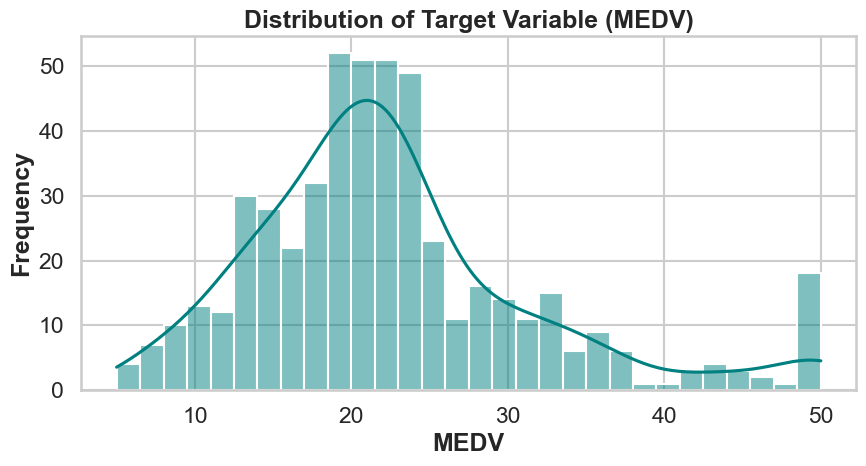

Target summary statistics:
count    505.000000
mean      22.529901
std        9.205991
min        5.000000
25%       17.000000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64


In [19]:

# Target distribution
plt.figure(figsize=(9, 5))
sns.histplot(boston_df['MEDV'], kde=True, bins=30, color='teal')
plt.title('Distribution of Target Variable (MEDV)')
plt.xlabel('MEDV')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

print("Target summary statistics:")
print(boston_df['MEDV'].describe())


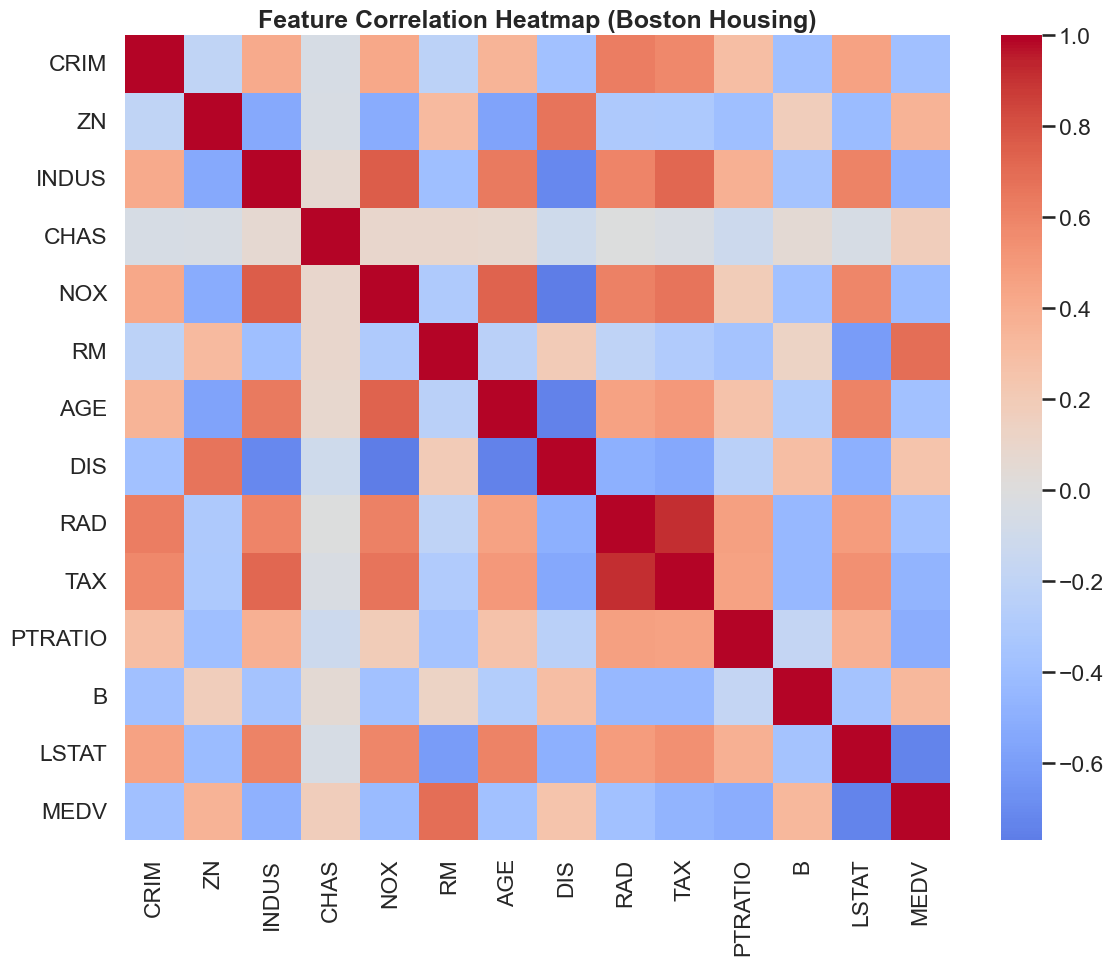

Correlation with MEDV:


,corr_with_MEDV
MEDV,1.000000
RM,0.695365
ZN,0.360393
B,0.333394
DIS,0.249896
CHAS,0.175364
AGE,-0.376932
RAD,-0.381690
CRIM,-0.388249
NOX,-0.427295


In [20]:

# Correlation analysis
corr = boston_df.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap (Boston Housing)')
plt.tight_layout()
plt.show()

corr_target = corr['MEDV'].sort_values(ascending=False)
print("Correlation with MEDV:")
display(corr_target.to_frame('corr_with_MEDV'))


### 14.1 Statistical Interpretation

For regression, Dataset **D** has $505$ tuples and continuous target `MEDV`, so statistical interpretation focuses on distribution shape, correlation structure, and implications for split quality.

Key empirical observations from EDA:
- `MEDV` is not perfectly symmetric; it shows concentration in mid-range values with thinner support at extremes.
- Correlation with `MEDV` is strongest in expected directions: `RM` is positively associated, while `LSTAT` is strongly negatively associated.
- Several predictors are mutually correlated, so univariate correlation should be interpreted as association, not isolated causal effect.

Decision-tree interpretation using your terminology:
- In regression trees, each split is chosen to reduce node impurity measured by variance (equivalently reduce RSS).
- Features with stronger target association (for example `LSTAT`, `RM`) are expected to provide larger early split gains because they separate subsets with more distinct local means.
- Because relationships are non-linear and interactive, one split is insufficient; subsets must be **split further** to reduce residual variance in child nodes.

Why this matters for model choice:
- A single tree can capture major structure but remains high-variance on moderate sample size.
- Bagging and Random Forest are statistically justified here because averaging across trees reduces variance while preserving non-linear partitioning.
- Therefore, we expect lower CV MSE and higher $R^2$ from ensembles relative to a standalone regression tree, which is consistent with your later results.

### Conceptual Reasoning: Minimum Leaf Size in Regression Trees

This cell sets up the baseline regression tree under the assignment stopping-rule requirement `S = 4`.

Why `min_samples_leaf = 4` matters:
- It prevents terminal nodes with very few samples, which reduces high-variance splits.
- It regularizes recursive binary splitting so the tree is less likely to memorize noise.
- It improves generalization compared with an unconstrained tree.

Protocol used in the next code cell:
- Build `X_b` and `y_b` with target `MEDV`.
- Create an explicit train/test split.
- Fit the regression tree only on training data.
- Visualize the trained tree (shown up to depth 4 for readability).



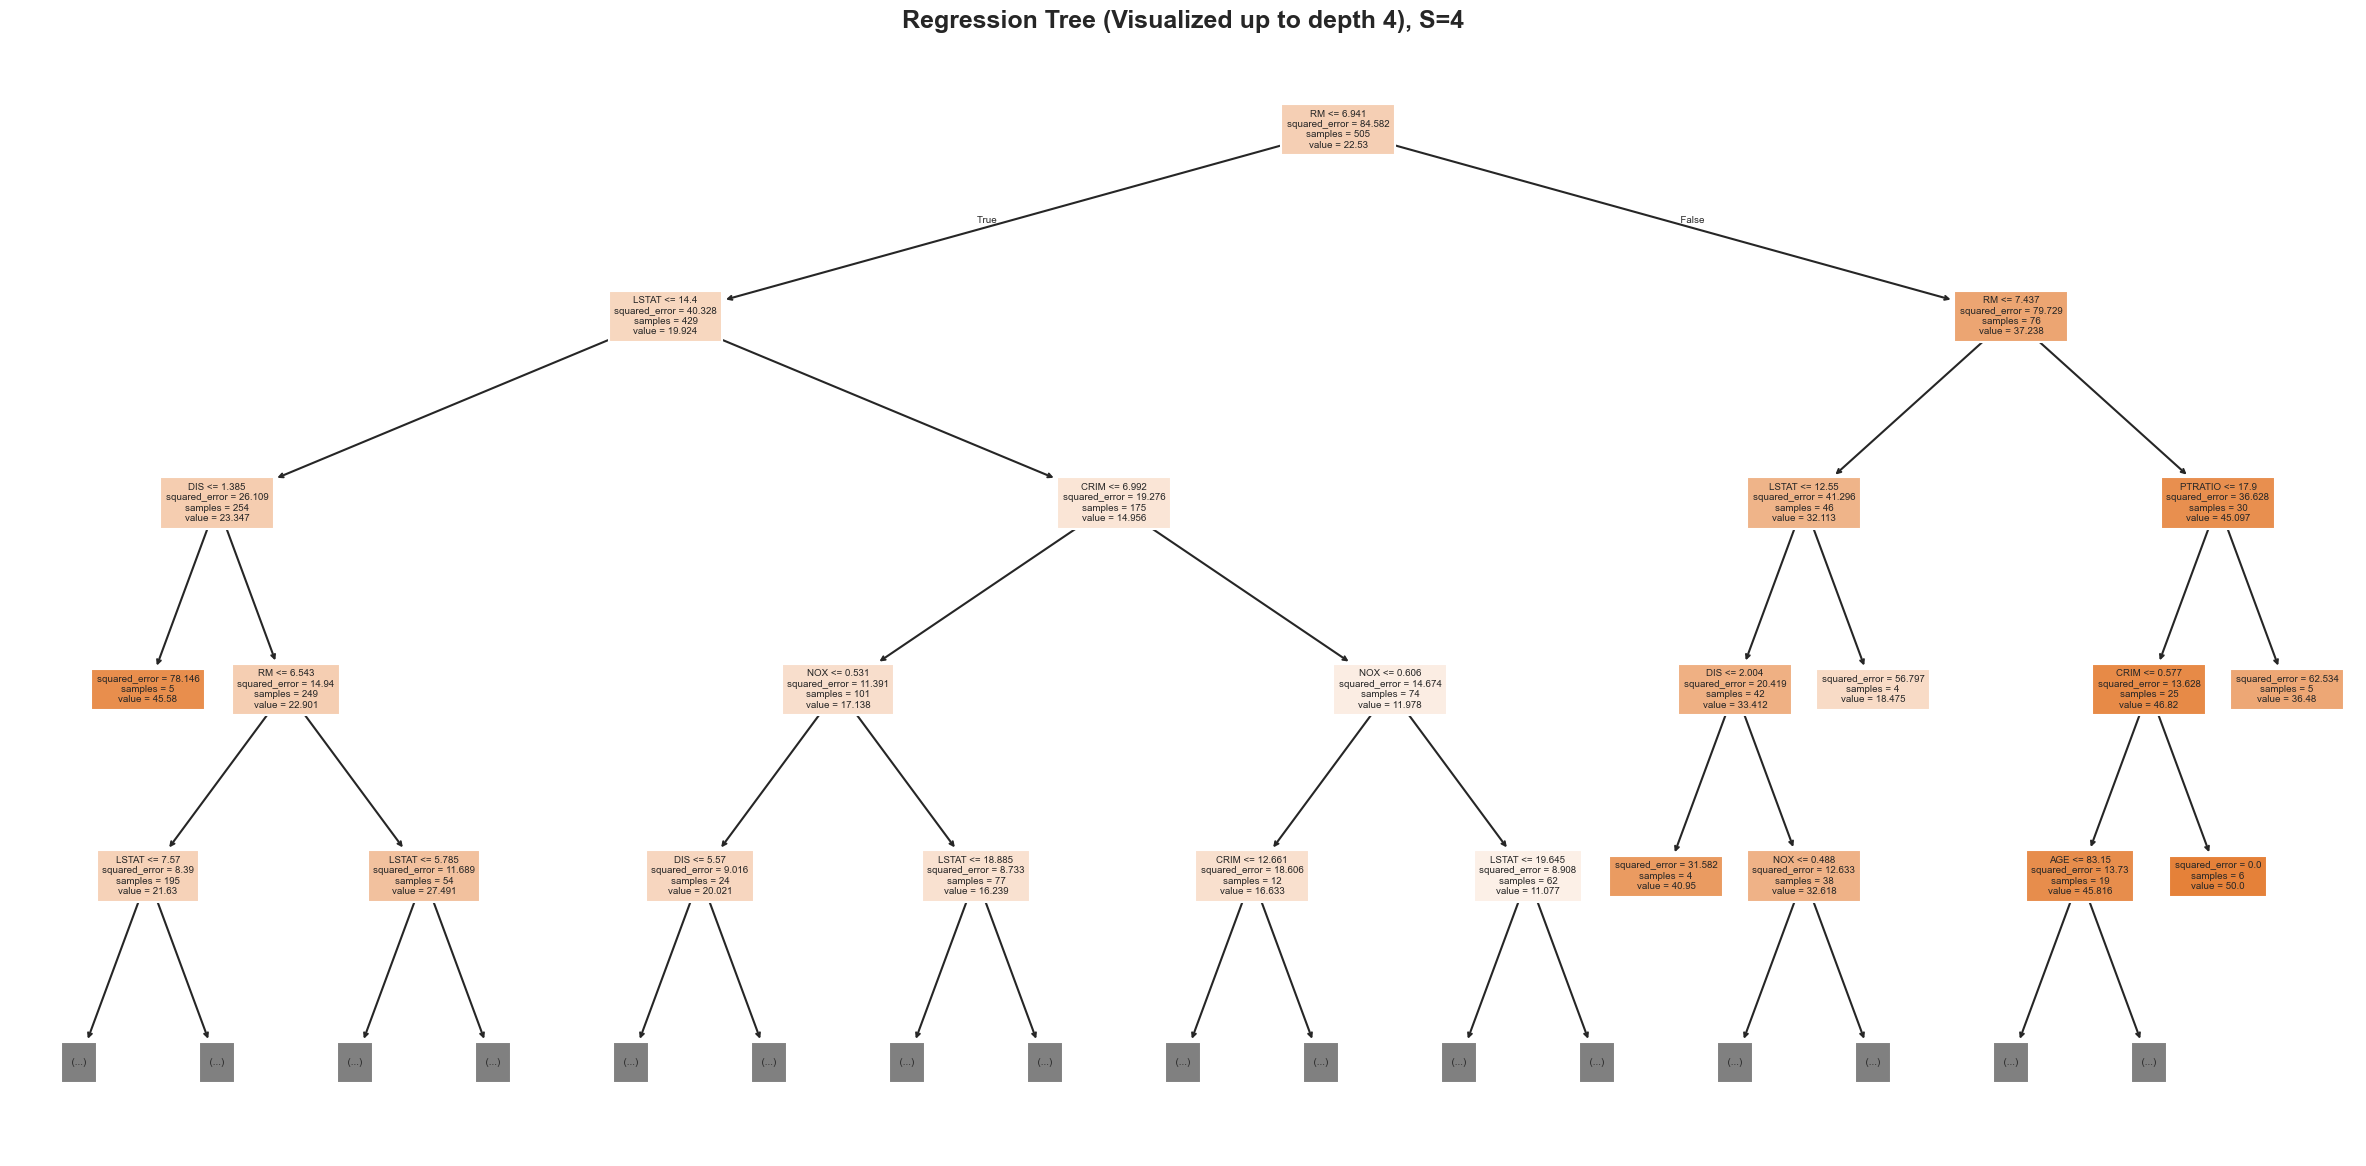

In [21]:
X_b = boston_df.drop(columns=['MEDV'])
y_b = boston_df['MEDV']

cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
S = 4

# Build the tree on training data (not full data) to match the assignment wording.
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b, y_b, test_size=0.2, random_state=RANDOM_STATE
)

reg_tree = DecisionTreeRegressor(min_samples_leaf=S, random_state=RANDOM_STATE)
reg_tree.fit(X_train_b, y_train_b)

plt.figure(figsize=(24, 12))
plot_tree(reg_tree, feature_names=X_b.columns, filled=True, fontsize=7, max_depth=4)
plt.title('Regression Tree (trained on training split, visualized up to depth 4), S=4')
plt.tight_layout()
plt.show()



## 16. Bagging Regression (Tune B using CV MSE)

### Conceptual Reasoning: Bagging Tuning for Regression

Goal: choose the number of bootstrapped trees `B` that minimizes cross-validated MSE.

Method implemented:
- Fix the base learner as `DecisionTreeRegressor(min_samples_leaf=S)` with `S=4`.
- Sweep `B` in `{50, 100, ..., 500}`.
- For each `B`, compute mean CV MSE with identical folds.
- Select `best_B_reg` as the `B` with smallest average CV MSE.

Interpretation:
- Increasing `B` mainly reduces variance through averaging.
- After a point, returns diminish, so the selected `B` balances performance and cost.



Best B (Bagging Regression): 250
Best CV MSE (Bagging): 13.6383


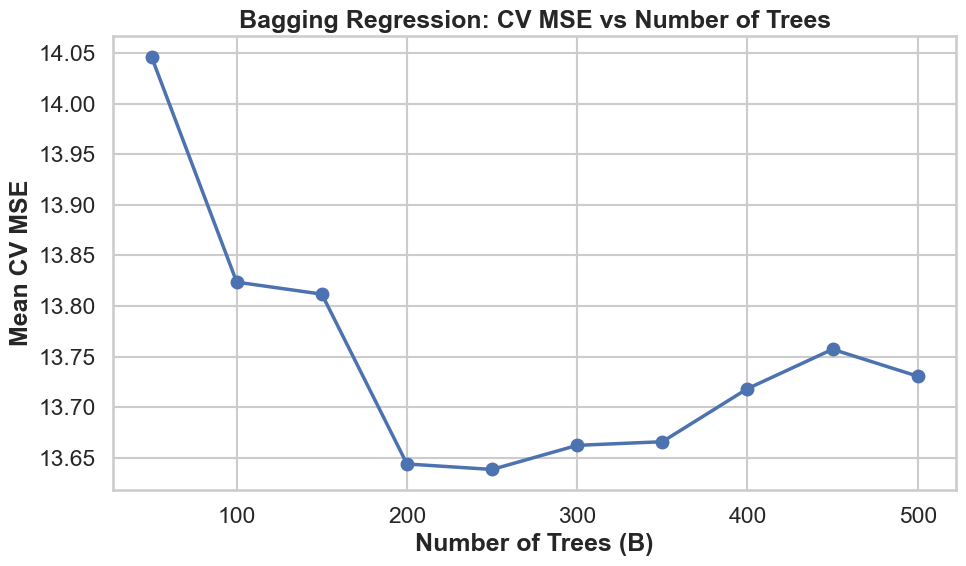

In [22]:

B_values_reg = list(range(50, 501, 50))
mse_bag = []

mse_scorer = make_scorer(mean_squared_error, greater_is_better=False)

for B in B_values_reg:
    bag_reg = BaggingRegressor(
        estimator=DecisionTreeRegressor(min_samples_leaf=S, random_state=RANDOM_STATE),
        n_estimators=B,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    neg_mse = cross_val_score(bag_reg, X_b, y_b, scoring=mse_scorer, cv=cv_reg, n_jobs=-1).mean()
    mse_bag.append(-neg_mse)

best_B_reg, best_bag_mse = best_by(B_values_reg, mse_bag, maximize=False)
print(f"Best B (Bagging Regression): {best_B_reg}")
print(f"Best CV MSE (Bagging): {best_bag_mse:.4f}")

plot_line(B_values_reg, mse_bag,
          'Bagging Regression: CV MSE vs Number of Trees',
          'Number of Trees (B)',
          'Mean CV MSE')


## 17. Random Forest Regression (m = 7)

### Conceptual Reasoning: Random Forest for Regression

Assignment requirement: evaluate feature subspace size `m` from `sqrt(d)` to `d`, then report performance for `m = 7` using the tuned `B` from bagging.

What this section does:
- Computes CV metrics for each `m` in `[sqrt(d), d]`.
- Summarizes the tradeoff curve (`m` vs CV MSE).
- Extracts and reports the required `m=7` metrics.

Why this matters:
- Larger `m` increases split strength but raises correlation between trees.
- Smaller `m` decorrelates trees but can increase bias.
- The sweep shows where this bias-variance tradeoff is best for this dataset.



In [23]:
d = X_b.shape[1]
m_min = int(np.sqrt(d))
m_values = list(range(m_min, d + 1))

# Sweep m from sqrt(d) to d using the tuned number of trees.
rf_grid_rows = []
for m in m_values:
    rf_tmp = RandomForestRegressor(
        n_estimators=best_B_reg,
        max_features=m,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    cv_r2 = cross_val_score(rf_tmp, X_b, y_b, scoring='r2', cv=cv_reg, n_jobs=-1).mean()
    cv_mse = -cross_val_score(rf_tmp, X_b, y_b, scoring='neg_mean_squared_error', cv=cv_reg, n_jobs=-1).mean()
    rf_grid_rows.append((m, cv_mse, cv_r2))

rf_grid_df = pd.DataFrame(rf_grid_rows, columns=['m', 'CV MSE', 'CV R^2'])
display(rf_grid_df)

# Required reporting at m=7
rf_m7_row = rf_grid_df.loc[rf_grid_df['m'] == 7].iloc[0]
rf_reg_cv_mse = float(rf_m7_row['CV MSE'])
rf_reg_cv_r2 = float(rf_m7_row['CV R^2'])

rf_reg = RandomForestRegressor(
    n_estimators=best_B_reg,
    max_features=7,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print(f"Feature count d = {d}; evaluated m in [{m_min}, {d}]")
print(f"Random Forest CV R^2 (m=7, B={best_B_reg}): {rf_reg_cv_r2:.4f}")
print(f"Random Forest CV MSE (m=7, B={best_B_reg}): {rf_reg_cv_mse:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(rf_grid_df['m'], rf_grid_df['CV MSE'], marker='o')
plt.title('Random Forest Regression: CV MSE vs m')
plt.xlabel('m (features considered per split)')
plt.ylabel('Mean CV MSE')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Random Forest CV R^2 (m=7, B=250): 0.8804
Random Forest CV MSE (m=7, B=250): 9.9691


## 18. Advanced Regression Diagnostics (Residuals + Learning Curve)

### Diagnostic Role of Residual Analysis

Hold-out evaluation produced MSE $=6.3268$, MAE $=1.8345$, and $R^2=0.8865$, indicating strong out-of-sample fit.

Residual diagnostics refine this interpretation statistically:
- **Residuals vs Predicted**: a cloud centered near zero with no strong trend supports low systematic bias in mean prediction.
- **Spread pattern**: if residual spread grows at higher predicted values, that signals mild heteroscedasticity; if spread is roughly constant, error variance is stable.
- **Residual histogram**: near-symmetric concentration around zero indicates balanced over/under-prediction; heavy tails indicate occasional large errors that can affect risk-sensitive use cases.

So these plots are not just visual add-ons; they test whether the good scalar metrics are supported by stable error structure.

Hold-out MSE: 6.3268
Hold-out MAE: 1.8345
Hold-out R^2: 0.8865


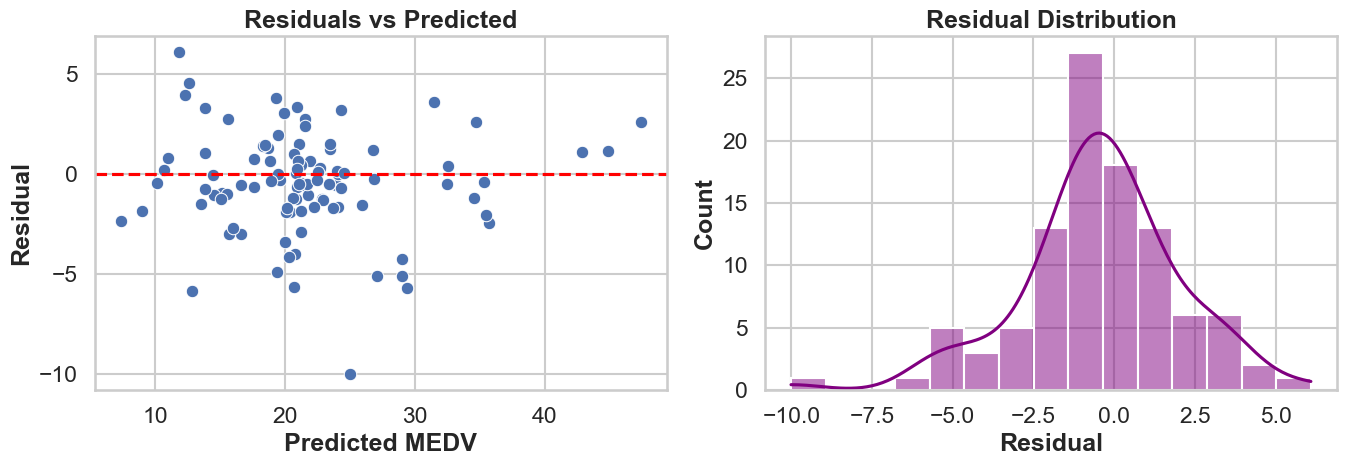

In [24]:

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_b, y_b, test_size=0.2, random_state=RANDOM_STATE
)

rf_reg.fit(X_train_r, y_train_r)
y_pred_r = rf_reg.predict(X_test_r)

mse_test = mean_squared_error(y_test_r, y_pred_r)
mae_test = mean_absolute_error(y_test_r, y_pred_r)
r2_test = r2_score(y_test_r, y_pred_r)

print(f"Hold-out MSE: {mse_test:.4f}")
print(f"Hold-out MAE: {mae_test:.4f}")
print(f"Hold-out R^2: {r2_test:.4f}")

residuals = y_test_r - y_pred_r

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=y_pred_r, y=residuals, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Predicted')
axes[0].set_xlabel('Predicted MEDV')
axes[0].set_ylabel('Residual')

sns.histplot(residuals, kde=True, ax=axes[1], color='purple')
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual')

plt.tight_layout()
plt.show()


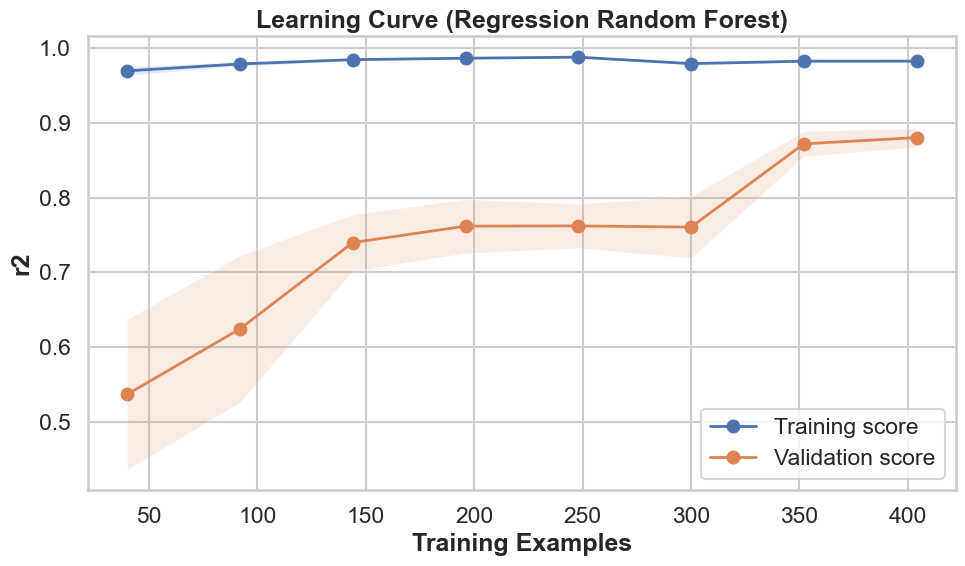

In [25]:

draw_learning_curve(
    estimator=rf_reg,
    X=X_b,
    y=y_b,
    cv=cv_reg,
    scoring='r2',
    title='Learning Curve (Regression Random Forest)'
)


## 19. Feature Importance Analysis (Regression RF)

### Interpretation of Feature Importance in Regression RF

Impurity-based importance scores quantify average reduction in node variance contributed by each feature across trees.
Higher-ranked features are statistically more influential for partitioning, but importance should be interpreted comparatively (relative ranking), not as direct causal impact.

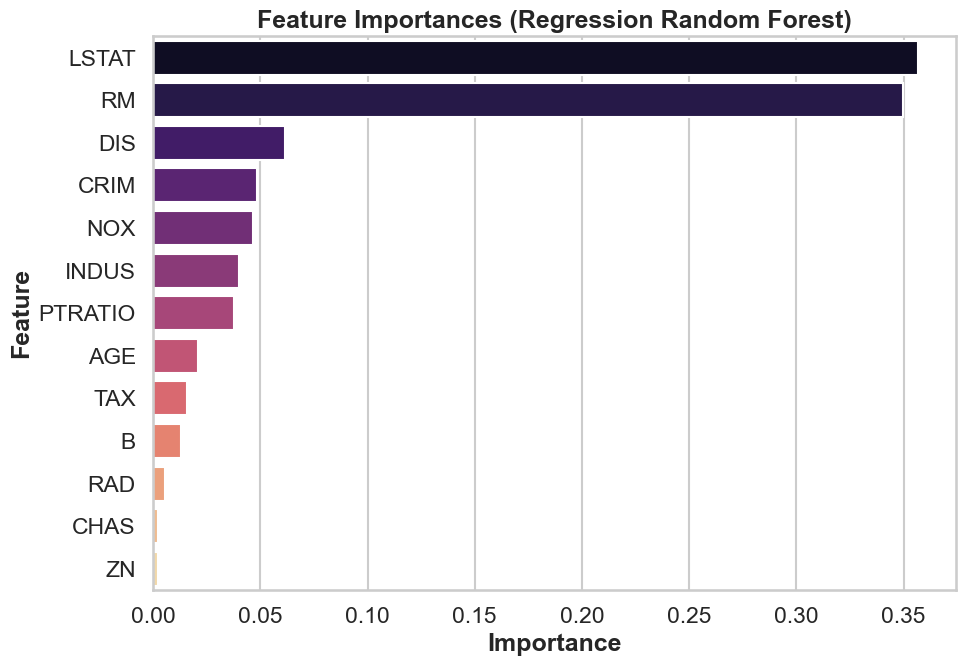

,importance
LSTAT,0.356654
RM,0.349683
DIS,0.061325
CRIM,0.048508
NOX,0.046552
INDUS,0.039950
PTRATIO,0.037575
AGE,0.020858
TAX,0.015938
B,0.013154


In [26]:

rf_reg.fit(X_b, y_b)
importance_reg = pd.Series(rf_reg.feature_importances_, index=X_b.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(x=importance_reg.values, y=importance_reg.index, palette='magma')
plt.title('Feature Importances (Regression Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

display(importance_reg.to_frame('importance'))


## 20. Regression Model Comparison Table

### Interpretation of Comparative Regression Results

Model ranking should be based on joint consideration of CV MSE (lower is better) and CV $R^2$ (higher is better). Because all models were evaluated under identical cross-validation protocol, observed differences can be attributed to modeling strategy rather than evaluation inconsistency.

Accordingly, the comparison isolates the empirical contribution of ensembling relative to a single-tree baseline.

In [27]:

# Baseline regression tree CV metrics for direct comparison
reg_tree_cv_mse = -cross_val_score(
    DecisionTreeRegressor(min_samples_leaf=S, random_state=RANDOM_STATE),
    X_b, y_b, scoring='neg_mean_squared_error', cv=cv_reg, n_jobs=-1
).mean()
reg_tree_cv_r2 = cross_val_score(
    DecisionTreeRegressor(min_samples_leaf=S, random_state=RANDOM_STATE),
    X_b, y_b, scoring='r2', cv=cv_reg, n_jobs=-1
).mean()

bag_reg_best = BaggingRegressor(
    estimator=DecisionTreeRegressor(min_samples_leaf=S, random_state=RANDOM_STATE),
    n_estimators=best_B_reg,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
bag_reg_cv_mse = -cross_val_score(bag_reg_best, X_b, y_b, scoring='neg_mean_squared_error', cv=cv_reg, n_jobs=-1).mean()
bag_reg_cv_r2 = cross_val_score(bag_reg_best, X_b, y_b, scoring='r2', cv=cv_reg, n_jobs=-1).mean()

regression_results = pd.DataFrame([
    ["Decision Tree Regressor", f"S={S}", reg_tree_cv_mse, reg_tree_cv_r2],
    ["Bagging Regressor", f"S={S}, B={best_B_reg}", bag_reg_cv_mse, bag_reg_cv_r2],
    ["Random Forest Regressor", f"m=7, B={best_B_reg}", rf_reg_cv_mse, rf_reg_cv_r2],
], columns=["Model", "Configuration", "CV MSE (Lower Better)", "CV R^2 (Higher Better)"])

regression_results = regression_results.sort_values("CV MSE (Lower Better)", ascending=True).reset_index(drop=True)
regression_results.index = regression_results.index + 1
regression_results


,Model,Configuration,CV MSE (Lower Better),CV R^2 (Higher Better)
1,Random Forest Regressor,"m=7, B=250",9.969110,0.880421
2,Bagging Regressor,"S=4, B=250",13.638271,0.838841
3,Decision Tree Regressor,S=4,20.114022,0.765799


## 21. Final Interpretation and Conclusions

### Classification

The Car Evaluation results show that controlling tree complexity and then aggregating trees is effective for imbalanced categorical prediction. The best single-tree model was at depth $T=14$ (CV accuracy $0.9780$), and bagging reached strong, stable performance with a relatively small ensemble ($B=50$). Random Forest with $m=4, B=50$ gave CV accuracy $0.9635$, while hold-out accuracy was $0.9711$.

Statistically, this pattern is consistent with a strong first split signal (high Gain on key attributes such as safety/person capacity) followed by deeper splits to separate mixed subsets. However, confusion concentration in minority classes indicates that aggregate accuracy still overstates reliability for rare classes.

### Regression

For Boston Housing ($n=505$), the results show a clear variance-reduction effect from ensembling. Bagging selected $B=250$ (CV MSE $13.6383$), and Random Forest with $m=7, B=250$ further improved to CV MSE $9.9691$ and CV $R^2=0.8804$. Hold-out performance (MSE $6.3268$, MAE $1.8345$, $R^2=0.8865$) together with residual diagnostics supports good out-of-sample fit.

In tree terms, strong predictors create early high-value variance-reduction splits, while additional recursive partitioning captures non-linear interactions. Ensemble averaging then reduces instability from any single partition path.

### Limitations

- The classification target is imbalanced, so minority-class errors remain a practical concern.
- The regression sample size is moderate, and results may be sensitive to data-split randomness despite cross-validation.
- Impurity-based feature importance is useful for ranking but is not causal inference.
 
